# Probe points and form

Everything in notebooks 02–04 used the values the CMM reported. The same file also
carries the **points those values were fitted to**, and they show things no reported
value does. This is where the four holes from
[`03-across-parts`](03-across-parts.ipynb) come back. Charts, no 3D.

Setup is in the [README](../README.md).

## Setup


`%autoreload 2` re-reads [`qifkit.py`](qifkit.py) before every cell, so an edit
to it takes effect without restarting the kernel.

Decoding the point sets is `qifkit.point_set` and `qifkit.measured_features`, in
section 4 of [`qifkit.py`](qifkit.py). Fitting and unrolling the cylinders is the
lesson, so that code is here.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

import qifkit

pd.set_option('display.width', 140)

import matplotlib.pyplot as plt

from qifkit import text

In [2]:
MODEL = '000454_D-MV-FH-2'
doc = qifkit.load(MODEL)
unit = qifkit.linear_unit(doc)

## What the numbers do not say

Each probed feature points at a point set: four binary arrays of points, normals,
probe radii and a compensation flag. Decoded for one part:

In [3]:
probed = qifkit.measured_features(doc, 'SN#1')
total_points = sum(len(f['points']['surface']) for f in probed)
print(f"SN#1: {len(probed)} probed features, {total_points} points")
print(f"compensated already: {probed[0]['points']['compensated'].any()}, "
      f"probe radius: {probed[0]['points']['radii'][0]:.5f} {unit}")

SN#1: 18 probed features, 708 points
compensated already: False, probe radius: 1.98256 mm


### Probe coverage

In [4]:
# Number of points the CMM probed on each face. This is coverage, which the
# characteristic table does not show.
coverage = {}
for feature in probed:
    hits = len(feature['points']['surface'])
    for entity in feature['entities']:
        coverage[int(entity)] = coverage.get(int(entity), 0) + hits

print(f'{len(coverage)} faces probed, '
      f'{min(coverage.values())}-{max(coverage.values())} points each')

18 faces probed, 20-174 points each


### Form

The file stores the CMM's *fit* (axis, direction, diameter) but no residual.
The residual is computed here, as the difference between each probe point and
the fitted cylinder.

In [5]:
def cylinder_residuals(feature):
    # Radial deviation of each probe point from the fitted cylinder.
    #
    # The fit is the CMM's, taken from the file: Axis/AxisPoint, Axis/Direction
    # and Diameter are the substitute geometry it already computed. The residual
    # is not stored anywhere. That part is ours.
    element = feature['element']
    points = feature['points']['surface']

    axis_point = np.array([float(x) for x in text(element, './qif:Axis/qif:AxisPoint').split()])
    axis = np.array([float(x) for x in text(element, './qif:Axis/qif:Direction').split()])
    axis = axis / np.linalg.norm(axis)
    radius = float(text(element, './qif:Diameter')) / 2

    offset = points - axis_point
    along = offset @ axis
    radial = offset - np.outer(along, axis)

    # any two directions perpendicular to the axis, to measure an angle against
    u = np.array([1.0, 0.0, 0.0])
    u = u - axis * (u @ axis)
    u /= np.linalg.norm(u)
    v = np.cross(axis, u)

    return {'diameter': 2 * radius,
            'axial': along,
            'theta': np.arctan2(radial @ v, radial @ u) % (2 * np.pi),
            'residual': np.linalg.norm(radial, axis=1) - radius}


cylinders = {f['name']: cylinder_residuals(f) for f in probed if f['type'] == 'Cylinder'}

print(f'{"feature":<18}{"diameter":>10}{"points":>8}{"levels":>8}{"largest gap":>13}')
for name, c in cylinders.items():
    angles = np.unique(np.round(np.degrees(c['theta'])))
    gaps = np.diff(np.concatenate([angles, [angles[0] + 360]]))
    # count rings by gap, not by rounding: a ring spans a few hundredths
    # of a mm and can straddle a rounding boundary
    levels = 1 + int((np.diff(np.sort(c['axial'])) > 0.5).sum())
    print(f'{name:<18}{c["diameter"]:>10.3f}{len(c["residual"]):>8}{levels:>8}'
          f'{gaps.max():>11.0f} deg')

feature             diameter  points  levels  largest gap
DATUM_B(5674)         22.099      24       4         60 deg
DATUM_C(5676)         14.030      20       4         73 deg
13__1(5678)            8.800      25       5         72 deg
13__2(5680)            8.793      25       5         74 deg
13__3(5682)            8.779      25       5         72 deg
13__4(5684)            8.764      25       5         72 deg
3__1(5686)            10.031      25       5         72 deg
10__1(5690)           43.813      40       5        142 deg
8__1(5688)            43.809      40       5        142 deg


Note the last column. Two of these bores were probed over about 218 degrees,
leaving a 142 degree gap. Every other cylinder was probed the whole way round.

In [6]:
from scipy.interpolate import griddata


def unrolled(cylinder, n_theta=240, n_axial=80):
    # Interpolate the residual over (angle, axial position), masking angles the
    # CMM never visited. Without the mask, Delaunay interpolation spans a gap that
    # falls inside the convex hull and produces a smooth surface where there is no
    # data. On this part that is about a third of a bore.
    theta, axial, residual = cylinder['theta'], cylinder['axial'], cylinder['residual']

    # tile +/-2pi so interpolation can close the seam where coverage is complete
    tiled_theta = np.concatenate([theta - 2 * np.pi, theta, theta + 2 * np.pi])
    tiled_axial = np.tile(axial, 3)
    tiled_residual = np.tile(residual, 3)

    theta_grid = np.linspace(0, 2 * np.pi, n_theta)
    axial_grid = np.linspace(axial.min(), axial.max(), n_axial)
    T, A = np.meshgrid(theta_grid, axial_grid)
    surface = griddata(np.column_stack([tiled_theta, tiled_axial]), tiled_residual, (T, A),
                       method='linear')

    # Mask any grid angle further from a probe than a typical column spacing.
    #
    # A CMM scan revisits the same angle at every axial level but drifts a
    # fraction of a degree doing it, so the sorted angles are clusters, not
    # distinct columns. Rather than cluster them, ignore the within-column gaps:
    # anything below a small fraction of the circle is drift, and the median of
    # what remains is the real column spacing.
    drift = 2 * np.pi / (4 * len(theta))
    gaps = np.diff(np.sort(np.concatenate([theta, theta[:1] + 2 * np.pi])))
    spacing = np.median(gaps[gaps > drift])

    theta_samples = np.unique(theta)
    distance = np.abs(((theta_grid[:, None] - theta_samples[None, :] + np.pi) % (2 * np.pi)) - np.pi)
    unprobed = distance.min(axis=1) > 0.75 * spacing
    surface[:, unprobed] = np.nan

    return theta_grid, axial_grid, surface, unprobed.mean()

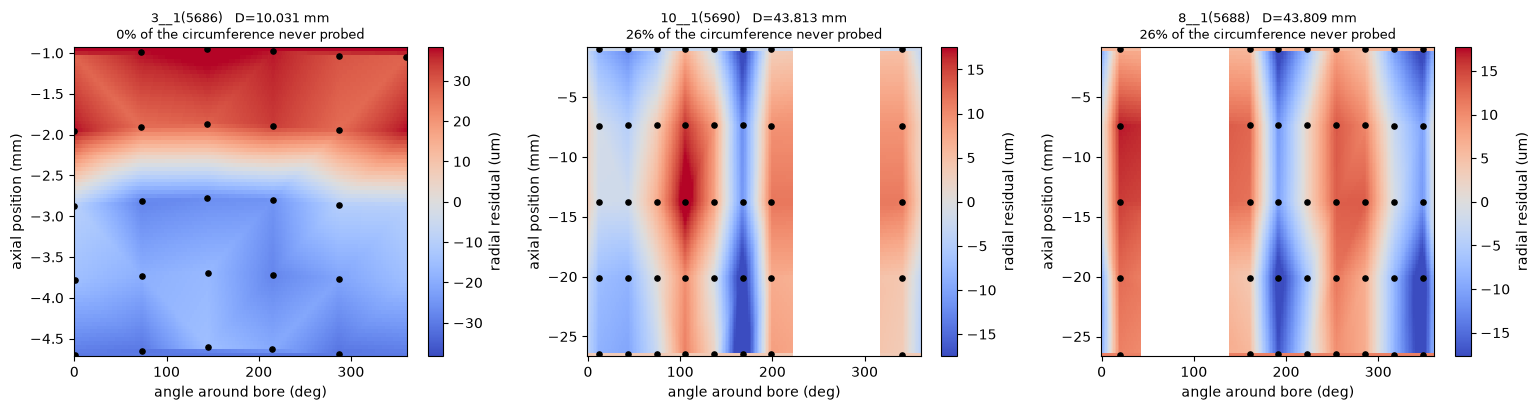

Black dots are actual probe hits. Everything between them is interpolation,
and white bands are angles the CMM never visited.


In [7]:
FEATURES = list(cylinders)[-3:]

fig, axes = plt.subplots(1, len(FEATURES), figsize=(5.2 * len(FEATURES), 4.2))
for ax, name in zip(np.atleast_1d(axes), FEATURES):
    cylinder = cylinders[name]
    theta_grid, axial_grid, surface, unprobed_fraction = unrolled(cylinder)

    # One bad hit can be 20x the real form. A percentile limit keeps the scale on
    # the signal instead of the outlier, which stays visible as a dark corner.
    limit = np.nanpercentile(np.abs(surface) * 1000, 98)

    image = ax.pcolormesh(np.degrees(theta_grid), axial_grid, surface * 1000,
                          cmap='coolwarm', vmin=-limit, vmax=limit, shading='auto')
    ax.scatter(np.degrees(cylinder['theta']), cylinder['axial'], c='k', s=14, zorder=3)
    ax.set_title(f'{name}   D={cylinder["diameter"]:.3f} {unit}\n'
                 f'{unprobed_fraction:.0%} of the circumference never probed', fontsize=9)
    ax.set_xlabel('angle around bore (deg)')
    ax.set_ylabel(f'axial position ({unit})')
    fig.colorbar(image, ax=ax, label='radial residual (um)')

plt.tight_layout()
plt.show()

print('Black dots are actual probe hits. Everything between them is interpolation,')
print('and white bands are angles the CMM never visited.')

### Size tolerance and form

A size tolerance controls size. It says nothing about shape, and on these bores
nothing else does either.

In [8]:
# What the size tolerance does and does not catch.
report = []
for name, cylinder in cylinders.items():
    residual = cylinder['residual'] * 1000
    robust = np.percentile(residual, 98) - np.percentile(residual, 2)
    report.append({'feature': name,
                   'diameter': round(cylinder['diameter'], 4),
                   'points': len(residual),
                   'formP2P_um': round(float(residual.max() - residual.min()), 1),
                   'formRobust_um': round(float(robust), 1)})

form = pd.DataFrame(report).set_index('feature')
print('Fits are least-squares (the file says so), so these are an upper bound on')
print('cylindricity, not cylindricity. With 5 points per circle, roundness is not')
print('available at all. This sampling supports taper and lobing.')
form

Fits are least-squares (the file says so), so these are an upper bound on
cylindricity, not cylindricity. With 5 points per circle, roundness is not
available at all. This sampling supports taper and lobing.


,diameter,points,formP2P_um,formRobust_um
feature,,,,
DATUM_B(5674),22.0987,24,17.4,15.2
DATUM_C(5676),14.0304,20,9.0,8.3
13__1(5678),8.8002,25,31.1,27.9
13__2(5680),8.7931,25,23.0,21.6
13__3(5682),8.7790,25,224.6,156.9
13__4(5684),8.7645,25,306.4,211.0
3__1(5686),10.0307,25,72.6,70.6
10__1(5690),43.8131,40,45.7,38.7
8__1(5688),43.8089,40,39.1,36.8
